# Exercise 49 – Comparing activation functions

**Week 9 · Neural networks**

The same network (1 → 8 → 8 → 1) is trained with four different activation
functions on data from a function with a kink,

$$g(x) = \begin{cases} x - 0.5 & x > 1.25 \\ 0.75 & x \le 1.25 \end{cases}$$

Each row is a different random initialisation.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.models import MLP
from comphy.plotting import setup_axes
from comphy.training import fit


def g(x, x0=1.25):
    return torch.where(x > x0, x - 0.5, torch.full_like(x, x0 - 0.5))


x_train = torch.arange(-0.5, 4.01, 0.5)
y_train = g(x_train)
xs = torch.linspace(-3, 4.5, 500)

First a look at the activation functions themselves:

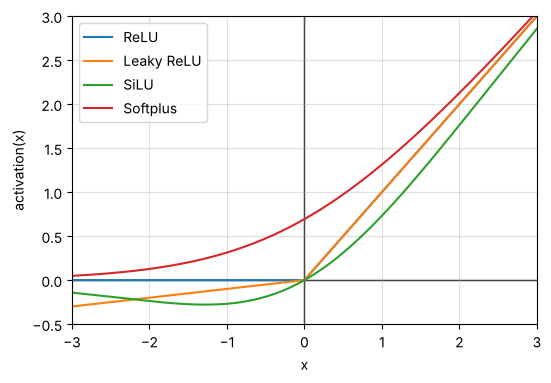

In [2]:
activations = {"ReLU": torch.relu, "Leaky ReLU": torch.nn.functional.leaky_relu,
               "SiLU": torch.nn.functional.silu, "Softplus": torch.nn.functional.softplus}

fig, ax = plt.subplots(figsize=(6, 4))
for name, func in activations.items():
    ax.plot(xs, func(xs, 0.1) if name == "Leaky ReLU" else func(xs), label=name)
setup_axes(ax, xlim=(-3, 3), ylim=(-0.5, 3), ylabel="activation(x)")
ax.legend()
plt.show()

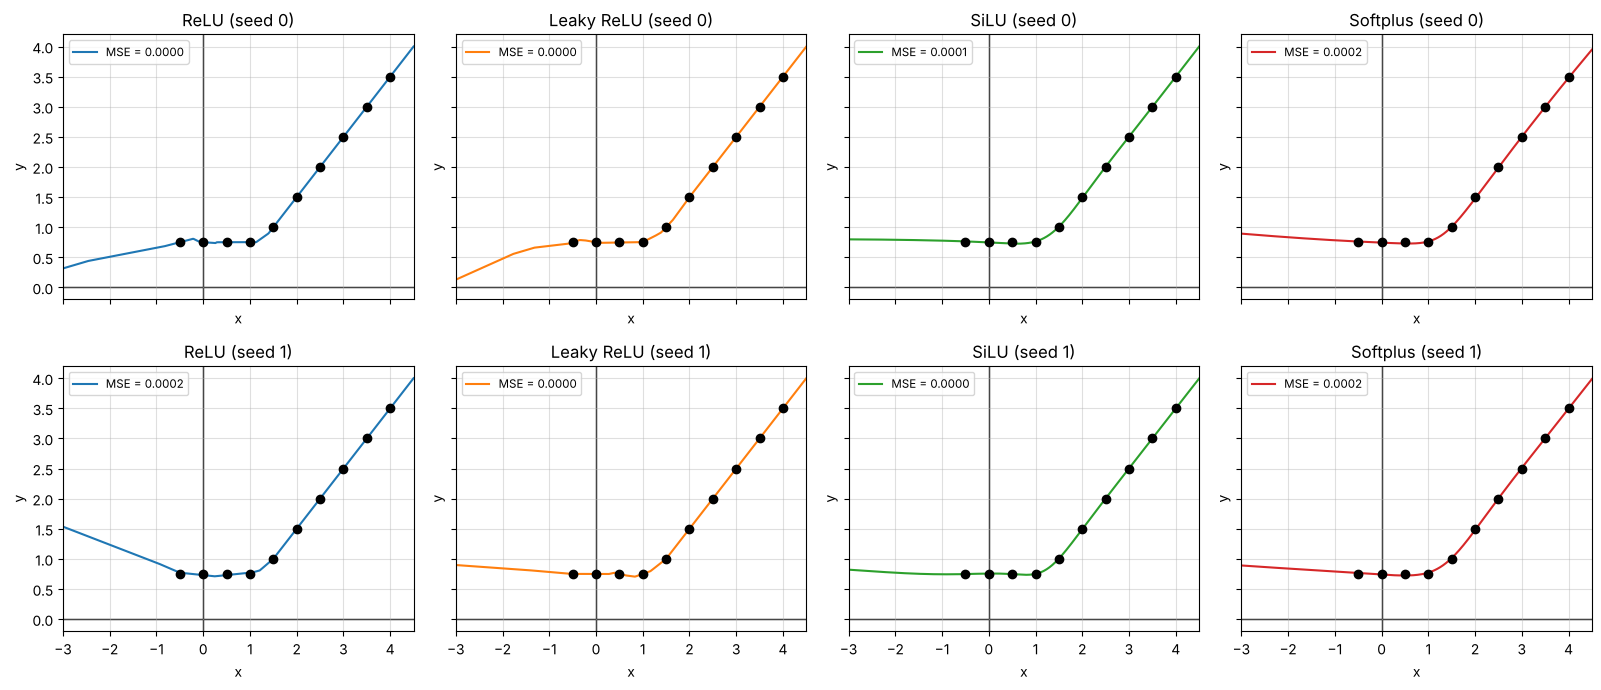

In [3]:
names = ["relu", "leaky_relu", "silu", "softplus"]
titles = list(activations)

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
for row in range(2):
    for col, (name, title) in enumerate(zip(names, titles)):
        torch.manual_seed(row)
        model = MLP(1, 1, hidden=(8, 8), activation=name)
        loss = fit(model, x_train, y_train, steps=2000)[-1]
        ax = axes[row, col]
        with torch.no_grad():
            ax.plot(xs, model(xs), color=f"C{col}", label=f"MSE = {loss:.4f}")
        ax.plot(x_train, y_train, "o", color="black")
        setup_axes(ax, xlim=(-3, 4.5), ylim=(-0.2, 4.2), title=f"{title} (seed {row})")
        ax.legend(loc="upper left", fontsize="small")
fig.tight_layout()
plt.show()

Inside the data range all four fit well. Outside it the networks extrapolate
differently: ReLU-type networks continue as straight lines, while SiLU and
Softplus give smooth curves.